## Import Packages

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import plotly

from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate, StratifiedKFold, train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.impute import KNNImputer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.metrics import (
    roc_auc_score, recall_score, accuracy_score, f1_score, precision_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
)

print("All core packages imported successfully.")

All core packages imported successfully.


In [2]:
from sklearn import set_config
from sklearn.ensemble import RandomForestClassifier

from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline

import optuna

optuna.logging.set_verbosity(optuna.logging.WARNING)
warnings.filterwarnings("ignore")
set_config(transform_output="pandas")

print("RandomForest, Optuna, imbalanced-learn imported successfully.")

RandomForest, Optuna, imbalanced-learn imported successfully.


d:\Churn modelling\churn_venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
from dotenv import load_dotenv
load_dotenv()

True

In [4]:
import dagshub
import mlflow

DAGSHUB_USER_TOKEN = os.getenv("DAGSHUB_USER_TOKEN")

dagshub.init(repo_owner='Ankitkumar1141', repo_name='Churn-modelling', mlflow=True)
mlflow.set_tracking_uri('https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow')
mlflow.set_experiment('Experiment 6 - RF HP Tuning')
print('MLflow tracking active on DagsHub.')

Accessing as Ankitkumar1141

Initialized MLflow to track repo "Ankitkumar1141/Churn-modelling"

Repository Ankitkumar1141/Churn-modelling initialized!

2026/11/11 19:17:58 INFO mlflow.tracking.fluent: Experiment with name 'Experiment 6 - RF HP Tuning' does not exist. Creating a new experiment.


MLflow tracking active on DagsHub.


In [5]:
try:
    mlflow.set_tracking_uri("https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow")
    mlflow.set_experiment("Experiment 6 - RF HP Tuning")
    print("MLflow tracking active on DagsHub.")
except Exception as e:
    print(f"[MLflow Notice] {e}")

MLflow tracking active on DagsHub.


In [6]:
df = pd.read_csv("preprocessed.csv")
print("Loaded dataset shape:", df.shape)
df.head(3)

Loaded dataset shape: (10000, 37)


,customer_id,name,gender,age,salary,location_id,churned,account_id,tenure,balance,...,is_single_product,inactive_senior,engagement_score,high_risk_inactive,is_female,geo_france,geo_germany,geo_spain,geo_uk,geo_usa
0,15634602,Hargrave,female,42,101348.88,2,1,A15634602SID,2,NaN,...,1,0,0.750000,0,1,1,0,0,0,0
1,15647311,Hill,female,41,112542.58,6,0,A15647311SID,1,83807.86,...,1,0,0.416667,0,1,0,0,0,0,1
2,15619304,Onio,female,42,113931.57,4,1,A15619304SID,8,159660.80,...,0,0,0.583333,0,1,0,0,0,1,0


## Exploratory Checks

In [7]:
df.dtypes

customer_id                  int64
name                        object
gender                      object
age                          int64
salary                     float64
location_id                  int64
churned                      int64
account_id                  object
tenure                       int64
balance                    float64
num_products                 int64
has_credit_card              int64
is_active                    int64
geography                   object
age_group                   object
salary_bracket              object
tenure_group                object
has_balance                  int64
churn_label                 object
has_credit_card_label       object
is_active_label             object
balance_to_salary          float64
balance_per_product        float64
age_when_joined              int64
products_per_tenure        float64
is_senior_risk               int64
is_extreme_product_risk      int64
is_single_product            int64
inactive_senior     

In [8]:
df.isna().sum().sort_values(ascending=False).head(5)

balance        3617
name              0
gender            0
age               0
customer_id       0
dtype: int64

In [9]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [10]:
print(df["churned"].value_counts())
churn_rate = df["churned"].mean()
print("\nChurn rate: {:.2%}".format(churn_rate))

churned
0    7963
1    2037
Name: count, dtype: int64

Churn rate: 20.37%


## Drop Unnecessary Columns

In [11]:
# Drop columns identified in prior notebooks as non-predictive or redundant.
# This matches the drop list in model_selection.ipynb and XGB_HP_Tuning.ipynb exactly.
drop_columns = [
    "has_balance",
    "products_per_tenure",
    "has_credit_card",
    "geo_france", "geo_uk", "geo_usa", "geo_spain", "geo_germany",
    "tenure", "salary",
    "customer_id",
    "account_id", "name", "location_id",
    "age_when_joined", "age",
    "churn_label",
    "has_credit_card_label",
    "is_active_label",
]

df = df.drop(columns=drop_columns)
print("Shape after dropping columns:", df.shape)
df.head(3)

Shape after dropping columns: (10000, 18)


,gender,churned,balance,num_products,is_active,geography,age_group,salary_bracket,tenure_group,balance_to_salary,balance_per_product,is_senior_risk,is_extreme_product_risk,is_single_product,inactive_senior,engagement_score,high_risk_inactive,is_female
0,female,1,NaN,1,1,france,36-45,high,new (0-2),0.000000,0.000000,0,0,1,0,0.750000,0,1
1,female,0,83807.86,1,1,usa,36-45,high,new (0-2),0.744670,83807.860000,0,0,1,0,0.416667,0,1
2,female,1,159660.80,3,0,uk,36-45,high,veteran (8-10),1.401362,53220.266667,0,1,0,0,0.583333,0,1


In [12]:
missing_cols = df.isna().any(axis=0).loc[lambda x: x].index.tolist()
print("Columns with missing values:", missing_cols)

Columns with missing values: ['balance']


In [13]:
pct_missing_rows = df.isna().any(axis=1).mean().round(4) * 100
n_missing = df.isna().any(axis=1).sum()
print(f"Rows with missing values: {pct_missing_rows:.2f}%  ({n_missing:,} rows)")

Rows with missing values: 36.17%  (3,617 rows)


## Train / Test Split

In [14]:
X = df.drop(columns="churned")
y = df["churned"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

print("Train size : {:,}  |  churn rate: {:.2%}".format(X_train.shape[0], y_train.mean()))
print("Test  size : {:,}  |  churn rate: {:.2%}".format(X_test.shape[0], y_test.mean()))

Train size : 8,000  |  churn rate: 20.38%
Test  size : 2,000  |  churn rate: 20.35%


In [15]:
print("Train shape:", X_train.shape)
print("Test  shape:", X_test.shape)
missing_in_train = X_train.isna().sum()
print("Missing in train (balance only):\n", missing_in_train[missing_in_train > 0])

Train shape: (8000, 17)
Test  shape: (2000, 17)
Missing in train (balance only):
 balance    2891
dtype: int64


## Column Type Identification

In [16]:
numeric_cols     = X.select_dtypes(include=["number"]).columns.tolist()
categorical_cols = X.select_dtypes(include=["object", "category", "string"]).columns.tolist()
binary_cols      = [c for c in numeric_cols if X[c].nunique() == 2]
scale_cols       = [c for c in numeric_cols if c not in binary_cols]

print("Numeric (to scale) :", scale_cols)
print("Binary pass-thru   :", binary_cols)
print("Categorical OHE    :", categorical_cols)

Numeric (to scale) : ['balance', 'num_products', 'balance_to_salary', 'balance_per_product', 'engagement_score']
Binary pass-thru   : ['is_active', 'is_senior_risk', 'is_extreme_product_risk', 'is_single_product', 'inactive_senior', 'high_risk_inactive', 'is_female']
Categorical OHE    : ['gender', 'geography', 'age_group', 'salary_bracket', 'tenure_group']


## Preprocessing Pipeline

In [17]:
preprocessor = ColumnTransformer(
    transformers=[
        ("scale",          MinMaxScaler(), scale_cols),
        ("nominal_encode", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), categorical_cols),
    ],
    remainder="passthrough",
    verbose_feature_names_out=False,
)
preprocessor.set_output(transform="pandas")

knn_imputer = KNNImputer(n_neighbors=10)

In [18]:
# Fit preprocessor + KNN imputer on training data only; transform both splits
base_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("knn_imputer",  knn_imputer),
])

X_train_trans = base_pipeline.fit_transform(X_train)
X_test_trans  = base_pipeline.transform(X_test)

print("X_train transformed shape:", X_train_trans.shape)
print("X_test  transformed shape:", X_test_trans.shape)

X_train transformed shape: (8000, 28)
X_test  transformed shape: (2000, 28)


In [19]:
sampler = RandomUnderSampler(random_state=42)

# Apply resampling to training data only (never to test set)
X_train_resampled, y_train_resampled = sampler.fit_resample(X_train_trans, y_train)

In [20]:
print("Before resampling — Train shape:", X_train_trans.shape)
print("Before resampling — Class distribution:")
print(y_train.value_counts())
print()
print("After  resampling — Train shape:", X_train_resampled.shape)
print("After  resampling — Class distribution:")
print(y_train_resampled.value_counts())

Before resampling — Train shape: (8000, 28)
Before resampling — Class distribution:
churned
0    6370
1    1630
Name: count, dtype: int64

After  resampling — Train shape: (3260, 28)
After  resampling — Class distribution:
churned
0    1630
1    1630
Name: count, dtype: int64


## Random Forest Hyperparameter Tuning with Optuna

| Hyperparameter | Search Space | Description |
|---|---|---|
| `n_estimators` | 100 – 800 | Number of trees in the forest |
| `max_depth` | 2 – 30 | Max depth per tree — controls complexity |
| `min_samples_split` | 2 – 20 | Min samples required to split an internal node |
| `min_samples_leaf` | 1 – 20 | Min samples required at a leaf node |
| `max_features` | sqrt / log2 / 0.3 / 0.5 / 0.7 | Fraction of features considered per split |
| `max_samples` | 0.5 – 1.0 | Fraction of samples drawn for each tree (bootstrap) |

> **Note:** `class_weight` is NOT needed here because Random UnderSampling already balances the training set.

In [21]:
def objective(trial):
    with mlflow.start_run(nested=True):
        params = {
            "n_estimators"      : trial.suggest_int("n_estimators", 100, 800),
            "max_depth"         : trial.suggest_int("max_depth", 2, 30),
            "min_samples_split" : trial.suggest_int("min_samples_split", 2, 20),
            "min_samples_leaf"  : trial.suggest_int("min_samples_leaf", 1, 20),
            "max_features"      : trial.suggest_categorical("max_features", ["sqrt", "log2", 0.3, 0.5, 0.7]),
            "max_samples"       : trial.suggest_float("max_samples", 0.5, 1.0),
            "random_state"      : 42,
            "n_jobs"            : -1,
        }

        # log all hyperparameters
        mlflow.log_params(params)

        # build the model
        rf = RandomForestClassifier(**params)

        # 5-fold stratified cross-validation on resampled training data
        cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

        cv_scores = cross_validate(
            rf,
            X_train_resampled,
            y_train_resampled,
            cv=cv,
            scoring={
                "roc_auc" : "roc_auc",
                "recall"  : "recall",
                "f1"      : "f1",
            },
            n_jobs=-1,
        )

        mean_roc_auc = cv_scores["test_roc_auc"].mean()
        mean_recall  = cv_scores["test_recall"].mean()
        mean_f1      = cv_scores["test_f1"].mean()

        # log CV metrics
        mlflow.log_metric("cv_mean_roc_auc", mean_roc_auc)
        mlflow.log_metric("cv_mean_recall",  mean_recall)
        mlflow.log_metric("cv_mean_f1",      mean_f1)

        return mean_roc_auc

In [22]:
# create Optuna study — maximise ROC-AUC
study = optuna.create_study(direction="maximize", study_name="rf_hp_tuning")

with mlflow.start_run(run_name="RF HP Tuning — Best Model") as parent:
    # optimize the objective function
    study.optimize(objective, n_trials=50, n_jobs=-1, show_progress_bar=True)

    # log the best parameters
    mlflow.log_params(study.best_params)

    # log the best score
    mlflow.log_metric("best_cv_roc_auc", study.best_value)

  0%|          | 0/50 [00:00<?, ?it/s]

🏃 View run sincere-dolphin-498 at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/5/runs/7e13b407337c49178305f1349388aa45
🧪 View experiment at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/5


Best trial: 2. Best value: 0.84438:   2%|▏         | 1/50 [00:29<24:29, 30.00s/it]

🏃 View run wistful-bat-153 at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/5/runs/aded743ab25c4538b83ad551977979ea
🧪 View experiment at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/5


Best trial: 2. Best value: 0.84438:   4%|▍         | 2/50 [00:37<13:19, 16.65s/it]

🏃 View run spiffy-fly-467 at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/5/runs/89fc3ecb695146638e8fdb8bd2397174
🧪 View experiment at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/5
🏃 View run defiant-bat-173 at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/5/runs/a2cbe355cffc461e8746cb8d51960c1b
🧪 View experiment at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/5


... (52 outputs left out)

Best trial: 23. Best value: 0.845276:  96%|█████████▌| 48/50 [10:05<00:17,  8.99s/it]

🏃 View run fun-hog-469 at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/5/runs/dd360a07b3cc4d1eb9f1514e80241a6d
🧪 View experiment at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/5
🏃 View run bold-cow-947 at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/5/runs/85d9d8f3cc084ff8ac0647ac478648b9
🧪 View experiment at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/5


Best trial: 23. Best value: 0.845276: 100%|██████████| 50/50 [10:20<00:00, 12.40s/it]


🏃 View run RF HP Tuning — Best Model at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/5/runs/a4e99e932a004dfda62939b7aa3cc2d6
🧪 View experiment at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/5


In [23]:
# best CV ROC-AUC achieved across all 50 trials
print("Best CV ROC-AUC :", round(study.best_value, 4))

Best CV ROC-AUC : 0.8453


In [24]:
# best hyperparameters found by Optuna
print("Best Parameters:")
for k, v in study.best_params.items():
    print(f"  {k:22s}: {v}")

Best Parameters:
  n_estimators          : 789
  max_depth             : 28
  min_samples_split     : 18
  min_samples_leaf      : 12
  max_features          : sqrt
  max_samples           : 0.9886262040195561


In [25]:
# full trials dataframe sorted by objective value
study.trials_dataframe().sort_values("value", ascending=False)

,number,value,datetime_start,datetime_complete,duration,params_max_depth,params_max_features,params_max_samples,params_min_samples_leaf,params_min_samples_split,params_n_estimators,state
23,23,0.845276,2026-11-11 19:20:44.038890,2026-11-11 19:23:09.632285,0 days 00:02:25.593395,28,sqrt,0.988626,12,18,789,COMPLETE
22,22,0.845151,2026-11-11 19:20:33.520344,2026-11-11 19:23:39.929146,0 days 00:03:06.408802,16,sqrt,0.988004,9,18,724,COMPLETE
20,20,0.845091,2026-11-11 19:20:19.852676,2026-11-11 19:23:24.787643,0 days 00:03:04.934967,8,sqrt,0.746836,10,6,304,COMPLETE
21,21,0.845069,2026-11-11 19:20:31.892103,2026-11-11 19:23:11.877661,0 days 00:02:39.985558,30,sqrt,0.722617,11,7,783,COMPLETE
30,30,0.845006,2026-11-11 19:22:57.881514,2026-11-11 19:25:23.952228,0 days 00:02:26.070714,25,sqrt,0.985137,13,17,692,COMPLETE
27,27,0.844967,2026-11-11 19:21:20.908097,2026-11-11 19:24:31.892577,0 days 00:03:10.984480,28,sqrt,0.703083,8,17,786,COMPLETE
13,13,0.844907,2026-11-11 19:18:45.234032,2026-11-11 19:20:31.886050,0 days 00:01:46.652018,18,sqrt,0.870320,7,14,651,COMPLETE
25,25,0.844893,2026-11-11 19:21:07.911534,2026-11-11 19:25:55.944551,0 days 00:04:48.033017,27,sqrt,0.985764,8,17,620,COMPLETE
36,36,0.844833,2026-11-11 19:23:39.936116,2026-11-11 19:26:52.068868,0 days 00:03:12.132752,26,sqrt,0.995461,13,17,800,COMPLETE
34,34,0.844831,2026-11-11 19:23:24.793575,2026-11-11 19:25:01.553180,0 days 00:01:36.759605,24,sqrt,0.992300,13,17,704,COMPLETE


## Optuna Visualisations

In [26]:
# optimization history plot
optuna.visualization.plot_optimization_history(study)

ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed

Figure({
    'data': [{'mode': 'markers',
              'name': 'Objective Value',
              'type': 'scatter',
              'x': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17,
                    18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33,
                    34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49],
              'y': [0.8436608453460799, 0.8428553953855997, 0.844379728254733,
                    0.8425260642101697, 0.8433559787722533, 0.8441651925175956,
                    0.8416227558432758, 0.8220990628175693, 0.8369274342278595,
                    0.8443383266212502, 0.8402470924761941, 0.8408511799465541,
                    0.8404766833527795, 0.844906658135421, 0.8445660356054049,
                    0.8410619518988295, 0.8442367044299747, 0.8296953216154165,
                    0.8444606496292671, 0.844381610147164, 0.8450910835936618,
                    0.8450685008844893, 0.8451513041514547, 0.8452755090519026,
                    0.8445716812826978, 0.8448934848884038, 0.8445999096691633,
                    0.844966878693214, 0.8447297602469043, 0.8445697993902668,
                    0.8450063984342655, 0.8440692160036132, 0.8444662953065603,
                    0.844778689450111, 0.8448313824381797, 0.8444060747487674,
                    0.8448332643306108, 0.8420141894689298, 0.8424545522977906,
                    0.8421346305845159, 0.8425693477360833, 0.8424978358237041,
                    0.8406074748767359, 0.8421572132936881, 0.8424620798675149,
                    0.8426126312619969, 0.8432769392901502, 0.8407759042493131,
                    0.8424865444691182, 0.8427330723775828]},
             {'mode': 'lines',
              'name': 'Best Value',
              'type': 'scatter',
              'x': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17,
                    18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33,
                    34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49],
              'y': [0.8436608453460799, 0.8436608453460799, 0.844379728254733,
                    0.844379728254733, 0.844379728254733, 0.844379728254733,
                    0.844379728254733, 0.844379728254733, 0.844379728254733,
                    0.844379728254733, 0.844379728254733, 0.844379728254733,
                    0.844379728254733, 0.844906658135421, 0.844906658135421,
                    0.844906658135421, 0.844906658135421, 0.844906658135421,
                    0.844906658135421, 0.844906658135421, 0.8450910835936618,
                    0.8450910835936618, 0.8451513041514547, 0.8452755090519026,
                    0.8452755090519026, 0.8452755090519026, 0.8452755090519026,
                    0.8452755090519026, 0.8452755090519026, 0.8452755090519026,
                    0.8452755090519026, 0.8452755090519026, 0.8452755090519026,
                    0.8452755090519026, 0.8452755090519026, 0.8452755090519026,
                    0.8452755090519026, 0.8452755090519026, 0.8452755090519026,
                    0.8452755090519026, 0.8452755090519026, 0.8452755090519026,
                    0.8452755090519026, 0.8452755090519026, 0.8452755090519026,
                    0.8452755090519026, 0.8452755090519026, 0.8452755090519026,
                    0.8452755090519026, 0.8452755090519026]},
             {'marker': {'color': '#cccccc'},
              'mode': 'markers',
              'name': 'Infeasible Trial',
              'showlegend': False,
              'type': 'scatter',
              'x': [],
              'y': []}],
    'layout': {'template': '...',
               'title': {'text': 'Optimization History Plot'},
               'xaxis': {'title': {'text': 'Trial'}},
               'yaxis': {'title': {'text': 'Objective Value'}}}
})

In [27]:
# hyperparameter importance plot
optuna.visualization.plot_param_importances(study)

ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed

Figure({
    'data': [{'cliponaxis': False,
              'hovertemplate': [max_samples (FloatDistribution):
                                0.003259232995628893<extra></extra>, n_estimators
                                (IntDistribution):
                                0.009697283222748446<extra></extra>,
                                min_samples_split (IntDistribution):
                                0.04827036537082835<extra></extra>,
                                min_samples_leaf (IntDistribution):
                                0.08779983789755334<extra></extra>, max_features
                                (CategoricalDistribution):
                                0.1746755202992414<extra></extra>, max_depth
                                (IntDistribution):
                                0.6762977602139995<extra></extra>],
              'name': 'Objective Value',
              'orientation': 'h',
              'text': [<0.01, <0.01, 0.05, 0.09, 0.17, 0.68],
              'textposition': 'outside',
              'type': 'bar',
              'x': [0.003259232995628893, 0.009697283222748446,
                    0.04827036537082835, 0.08779983789755334, 0.1746755202992414,
                    0.6762977602139995],
              'y': [max_samples, n_estimators, min_samples_split,
                    min_samples_leaf, max_features, max_depth]}],
    'layout': {'template': '...',
               'title': {'text': 'Hyperparameter Importances'},
               'xaxis': {'title': {'text': 'Hyperparameter Importance'}},
               'yaxis': {'title': {'text': 'Hyperparameter'}}}
})

In [28]:
# slice plot -- individual parameter effect on objective
optuna.visualization.plot_slice(study)

ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed

Figure({
    'data': [{'marker': {'color': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,
                                   14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25,
                                   26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37,
                                   38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49],
                         'colorbar': {'title': {'text': 'Trial'}, 'x': 1.0, 'xpad': 40},
                         'colorscale': [[0.0, 'rgb(247,251,255)'], [0.125,
                                        'rgb(222,235,247)'], [0.25,
                                        'rgb(198,219,239)'], [0.375,
                                        'rgb(158,202,225)'], [0.5,
                                        'rgb(107,174,214)'], [0.625,
                                        'rgb(66,146,198)'], [0.75,
                                        'rgb(33,113,181)'], [0.875,
                                        'rgb(8,81,156)'], [1.0, 'rgb(8,48,107)']],
                         'line': {'color': 'Grey', 'width': 0.5},
                         'showscale': True},
              'mode': 'markers',
              'name': 'Feasible Trial',
              'showlegend': False,
              'type': 'scatter',
              'x': [20, 21, 7, 18, 5, 9, 21, 2, 25, 14, 14, 12, 11, 18, 16, 20, 9,
                    2, 29, 15, 8, 30, 16, 28, 29, 27, 30, 28, 16, 30, 25, 25, 28,
                    30, 24, 25, 26, 27, 27, 23, 22, 22, 5, 27, 27, 22, 7, 5, 19,
                    19],
              'xaxis': 'x',
              'y': [0.8436608453460799, 0.8428553953855997, 0.844379728254733,
                    0.8425260642101697, 0.8433559787722533, 0.8441651925175956,
                    0.8416227558432758, 0.8220990628175693, 0.8369274342278595,
                    0.8443383266212502, 0.8402470924761941, 0.8408511799465541,
                    0.8404766833527795, 0.844906658135421, 0.8445660356054049,
                    0.8410619518988295, 0.8442367044299747, 0.8296953216154165,
                    0.8444606496292671, 0.844381610147164, 0.8450910835936618,
                    0.8450685008844893, 0.8451513041514547, 0.8452755090519026,
                    0.8445716812826978, 0.8448934848884038, 0.8445999096691633,
                    0.844966878693214, 0.8447297602469043, 0.8445697993902668,
                    0.8450063984342655, 0.8440692160036132, 0.8444662953065603,
                    0.844778689450111, 0.8448313824381797, 0.8444060747487674,
                    0.8448332643306108, 0.8420141894689298, 0.8424545522977906,
                    0.8421346305845159, 0.8425693477360833, 0.8424978358237041,
                    0.8406074748767359, 0.8421572132936881, 0.8424620798675149,
                    0.8426126312619969, 0.8432769392901502, 0.8407759042493131,
                    0.8424865444691182, 0.8427330723775828],
              'yaxis': 'y'},
             {'marker': {'color': [0, 6, 13, 14, 16, 17, 18, 20, 21, 22, 23, 24,
                                   25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36,
                                   1, 9, 19, 46, 48, 49, 2, 3, 4, 5, 10, 7, 8, 37,
                                   38, 39, 40, 41, 42, 43, 44, 45, 47, 11, 12, 15],
                         'colorbar': {'title': {'text': 'Trial'}, 'x': 1.0, 'xpad': 40},
                         'colorscale': [[0.0, 'rgb(247,251,255)'], [0.125,
                                        'rgb(222,235,247)'], [0.25,
                                        'rgb(198,219,239)'], [0.375,
                                        'rgb(158,202,225)'], [0.5,
                                        'rgb(107,174,214)'], [0.625,
                                        'rgb(66,146,198)'], [0.75,
                                        'rgb(33,113,181)'], [0.875,
                                        'rgb(8,81,156)'], [1.0, 'rgb(8,48,107)']],
                         'line': {'color': 'Grey', 'width': 0.5},
                         'showscale':

In [29]:
# parallel coordinate plot -- interactions between key RF params
optuna.visualization.plot_parallel_coordinate(
    study,
    params=["n_estimators", "max_depth", "min_samples_split", "min_samples_leaf", "max_features"]
)

ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed

Figure({
    'data': [{'dimensions': [{'label': 'Objective Value',
                              'range': [0.8220990628175693, 0.8452755090519026],
                              'values': [0.8436608453460799, 0.8428553953855997,
                                         0.844379728254733, 0.8425260642101697,
                                         0.8433559787722533, 0.8441651925175956,
                                         0.8416227558432758, 0.8220990628175693,
                                         0.8369274342278595, 0.8443383266212502,
                                         0.8402470924761941, 0.8408511799465541,
                                         0.8404766833527795, 0.844906658135421,
                                         0.8445660356054049, 0.8410619518988295,
                                         0.8442367044299747, 0.8296953216154165,
                                         0.8444606496292671, 0.844381610147164,
                                         0.8450910835936618, 0.8450685008844893,
                                         0.8451513041514547, 0.8452755090519026,
                                         0.8445716812826978, 0.8448934848884038,
                                         0.8445999096691633, 0.844966878693214,
                                         0.8447297602469043, 0.8445697993902668,
                                         0.8450063984342655, 0.8440692160036132,
                                         0.8444662953065603, 0.844778689450111,
                                         0.8448313824381797, 0.8444060747487674,
                                         0.8448332643306108, 0.8420141894689298,
                                         0.8424545522977906, 0.8421346305845159,
                                         0.8425693477360833, 0.8424978358237041,
                                         0.8406074748767359, 0.8421572132936881,
                                         0.8424620798675149, 0.8426126312619969,
                                         0.8432769392901502, 0.8407759042493131,
                                         0.8424865444691182, 0.8427330723775828]},
                             {'label': 'max_depth',
                              'range': [2, 30],
                              'values': [20, 21, 7, 18, 5, 9, 21, 2, 25, 14, 14,
                                         12, 11, 18, 16, 20, 9, 2, 29, 15, 8, 30,
                                         16, 28, 29, 27, 30, 28, 16, 30, 25, 25,
                                         28, 30, 24, 25, 26, 27, 27, 23, 22, 22, 5,
                                         27, 27, 22, 7, 5, 19, 19]},
                             {'label': 'max_features',
                              'range': [0, 4],
                              'ticktext': [sqrt, log2, 0.3, 0.5, 0.7],
                              'tickvals': [0, 1, 2, 3, 4],
                              'values': [0, 1, 2, 2, 2, 2, 0, 3, 3, 1, 2, 4, 4, 0,
                                         0, 4, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0,
                                         0, 0, 0, 0, 0, 0, 0, 0, 0, 3, 3, 3, 3, 3,
                                         3, 3, 3, 3, 1, 3, 1, 1]},
                             {'label': 'min_samples_leaf',
                              'range': [1, 19],
                              'values': [6, 15, 11, 7, 5, 14, 19, 17, 2, 9, 1, 17,
                                         10, 7, 7, 12, 3, 11, 10, 14, 10, 11, 9,
                                         12, 8, 8, 8, 8, 7, 13, 13, 4, 8, 8, 13,
                                         13, 13, 10, 11, 11, 11, 11, 11, 10, 11,
                                         11, 16, 11, 15, 16]},
                             {'label': 'min_samples_split',
                              'range': [2, 20],
                              'values': [3, 10, 7, 8, 15, 13, 20, 20, 14, 3, 15,
                                         2, 10, 14, 19, 18, 7, 7, 6, 7, 6, 7, 18,
                  

## Train Best Model & Evaluate on Test Set

In [30]:
# Build best RandomForest model with Optuna-tuned parameters
best_params = study.best_params.copy()
best_params.update({
    "random_state" : 42,
    "n_jobs"       : -1,
})

best_rf = RandomForestClassifier(**best_params)

# Train on resampled training data
best_rf.fit(X_train_resampled, y_train_resampled)
print("Best RandomForest model trained.")

Best RandomForest model trained.


In [31]:
# Predictions on the full (unresampled) train and test sets
y_pred_train = best_rf.predict(X_train_trans)
y_pred_test  = best_rf.predict(X_test_trans)
y_prob_train = best_rf.predict_proba(X_train_trans)[:, 1]
y_prob_test  = best_rf.predict_proba(X_test_trans)[:, 1]

train_acc = accuracy_score(y_train, y_pred_train)
test_acc  = accuracy_score(y_test, y_pred_test)
train_rec = recall_score(y_train, y_pred_train)
test_rec  = recall_score(y_test, y_pred_test)
train_auc = roc_auc_score(y_train, y_prob_train)
test_auc  = roc_auc_score(y_test, y_prob_test)

print(f"Train accuracy : {train_acc:.4f}")
print(f"Test  accuracy : {test_acc:.4f}")
print(f"Train recall   : {train_rec:.4f}")
print(f"Test  recall   : {test_rec:.4f}")
print(f"Train ROC-AUC  : {train_auc:.4f}")
print(f"Test  ROC-AUC  : {test_auc:.4f}")

Train accuracy : 0.7864
Test  accuracy : 0.7725
Train recall   : 0.7773
Test  recall   : 0.7420
Train ROC-AUC  : 0.8708
Test  ROC-AUC  : 0.8462


In [32]:
print("\n=== Classification Report (Test Set) ===")
print(classification_report(y_test, y_pred_test, target_names=["Stayed", "Churned"]))


=== Classification Report (Test Set) ===
              precision    recall  f1-score   support

      Stayed       0.92      0.78      0.85      1593
     Churned       0.46      0.74      0.57       407

    accuracy                           0.77      2000
   macro avg       0.69      0.76      0.71      2000
weighted avg       0.83      0.77      0.79      2000



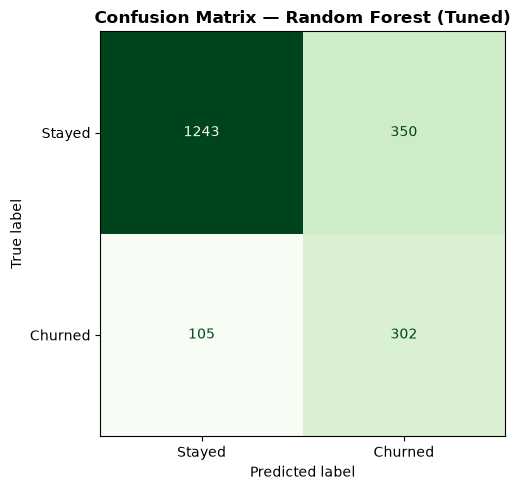

In [33]:
# Confusion Matrix
fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred_test)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Stayed", "Churned"])
disp.plot(ax=ax, colorbar=False, cmap="Greens")
ax.set_title("Confusion Matrix — Random Forest (Tuned)", fontweight="bold")
plt.tight_layout()
plt.show()

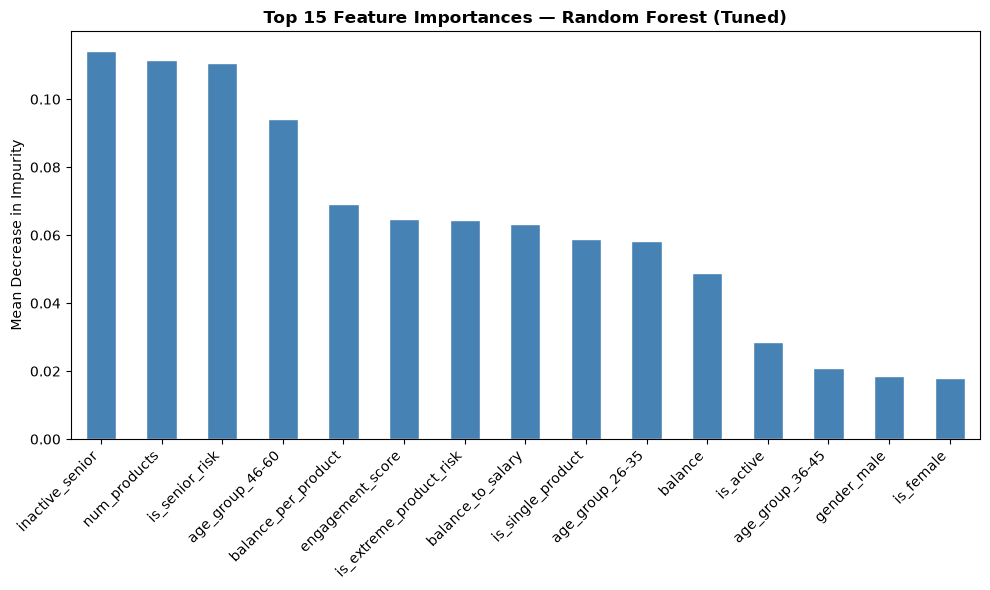

In [34]:
# Feature importances from best Random Forest
feat_imp = pd.Series(
    best_rf.feature_importances_,
    index=X_train_resampled.columns,
).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))
feat_imp.head(15).plot(kind="bar", ax=ax, color="steelblue", edgecolor="white")
ax.set_title("Top 15 Feature Importances — Random Forest (Tuned)", fontweight="bold")
ax.set_ylabel("Mean Decrease in Impurity")
ax.set_xlabel("")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## Cross-Validation

In [35]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    "roc_auc"  : "roc_auc",
    "recall"   : "recall",
    "precision": "precision",
    "f1"       : "f1",
    "accuracy" : "accuracy",
}

In [36]:
# Full end-to-end pipeline: preprocessor + KNN imputer + resampler + best RF
# This correctly prevents data leakage across each CV fold
cv_pipeline = ImbPipeline(steps=[
    ("preprocessor", preprocessor),
    ("knn_imputer",  KNNImputer(n_neighbors=10)),
    ("sampler",      RandomUnderSampler(random_state=42)),
    ("classifier",   best_rf),
])

cv_results = cross_validate(
    cv_pipeline,
    X_train,       # raw X_train — pipeline handles preprocessing inside each fold
    y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=False,
    n_jobs=1,
)

results_df = pd.DataFrame(cv_results)
results_df

,fit_time,score_time,test_roc_auc,test_recall,test_precision,test_f1,test_accuracy
0,5.930311,2.304763,0.836048,0.733129,0.465887,0.569726,0.774375
1,5.377469,2.292777,0.854321,0.751534,0.450368,0.563218,0.762500
2,5.308832,2.385420,0.840286,0.717791,0.436567,0.542923,0.753750
3,5.478114,2.301449,0.815729,0.687117,0.446215,0.541063,0.762500
4,5.310204,2.422425,0.835923,0.726994,0.451429,0.556992,0.764375


In [37]:
print("=== CV Summary (5-Fold Stratified) ===")
print(f"Mean CV ROC-AUC  : {results_df['test_roc_auc'].mean():.4f} +/- {results_df['test_roc_auc'].std():.4f}")
print(f"Mean CV Recall   : {results_df['test_recall'].mean():.4f} +/- {results_df['test_recall'].std():.4f}")
print(f"Mean CV Precision: {results_df['test_precision'].mean():.4f} +/- {results_df['test_precision'].std():.4f}")
print(f"Mean CV F1       : {results_df['test_f1'].mean():.4f} +/- {results_df['test_f1'].std():.4f}")
print(f"Mean CV Accuracy : {results_df['test_accuracy'].mean():.4f} +/- {results_df['test_accuracy'].std():.4f}")

=== CV Summary (5-Fold Stratified) ===
Mean CV ROC-AUC  : 0.8365 +/- 0.0138
Mean CV Recall   : 0.7233 +/- 0.0237
Mean CV Precision: 0.4501 +/- 0.0106
Mean CV F1       : 0.5548 +/- 0.0125
Mean CV Accuracy : 0.7635 +/- 0.0074


## Log Experiment to MLflow

In [38]:
try:
    with mlflow.start_run(run_name="RF HP Tuning — Final Evaluation"):
        mlflow.log_param("experiment_type",    "RF Hyperparameter Tuning")
        mlflow.log_param("imbalance_strategy", "RandomUnderSampler")
        mlflow.log_param("imputer",            "KNNImputer(n_neighbors=10)")
        mlflow.log_param("n_optuna_trials",    50)
        mlflow.log_param("dataset_rows",       X.shape[0])
        mlflow.log_param("dataset_features",   X.shape[1])
        mlflow.log_params(best_params)

        mlflow.log_metric("training_accuracy", accuracy_score(y_train, y_pred_train))
        mlflow.log_metric("training_recall",   recall_score(y_train, y_pred_train))
        mlflow.log_metric("training_roc_auc",  roc_auc_score(y_train, y_prob_train))
        mlflow.log_metric("test_accuracy",     accuracy_score(y_test, y_pred_test))
        mlflow.log_metric("test_recall",       recall_score(y_test, y_pred_test))
        mlflow.log_metric("test_precision",    precision_score(y_test, y_pred_test))
        mlflow.log_metric("test_f1",           f1_score(y_test, y_pred_test))
        mlflow.log_metric("test_roc_auc",      roc_auc_score(y_test, y_prob_test))
        mlflow.log_metric("cv_mean_recall",    results_df["test_recall"].mean())
        mlflow.log_metric("cv_mean_roc_auc",   results_df["test_roc_auc"].mean())
        mlflow.log_metric("cv_mean_f1",        results_df["test_f1"].mean())
        mlflow.log_metric("optuna_best_cv_roc_auc", study.best_value)

        for i, s in enumerate(results_df["test_roc_auc"]):
            mlflow.log_metric("cv_roc_auc_fold", s, step=i)
        for i, s in enumerate(results_df["test_recall"]):
            mlflow.log_metric("cv_recall_fold", s, step=i)

        # log model artifact with signature
        signature = mlflow.models.infer_signature(
            model_input=X_train_resampled.sample(20, random_state=42),
            model_output=best_rf.predict_proba(X_train_resampled.sample(20, random_state=42))[:, 1],
        )
        mlflow.sklearn.log_model(best_rf, artifact_path="rf_tuned_model", signature=signature)

    print("Experiment logged to MLflow.")
except Exception as e:
    print(f"[MLflow Notice] {e}")

2026/11/11 19:39:04 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


🏃 View run RF HP Tuning — Final Evaluation at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/5/runs/bcff00ae8a2c4a6484df270c173e5a69
🧪 View experiment at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/5
Experiment logged to MLflow.


## Final Summary

In [39]:
summary = pd.DataFrame({
    "Metric": [
        "Test ROC-AUC", "Test Recall", "Test Precision", "Test F1", "Test Accuracy",
        "CV ROC-AUC (mean)", "CV Recall (mean)", "CV F1 (mean)", "CV Accuracy (mean)",
    ],
    "Exp 4: XGB Spot-Check": [
        0.8473, 0.7224, 0.4696, 0.5692, 0.7775,
        0.8368, 0.7178, 0.5607, 0.7707,
    ],
    "Exp 5: XGB HP Tuning": [
        0.8492, 0.7518, 0.4525, 0.5736, 0.7725,
        0.8389, 0.7209, 0.5558, 0.7653,
    ],
    "Exp 6: RF HP Tuning (This Notebook)": [
        round(roc_auc_score(y_test, y_prob_test),    4),
        round(recall_score(y_test, y_pred_test),     4),
        round(precision_score(y_test, y_pred_test),  4),
        round(f1_score(y_test, y_pred_test),         4),
        round(accuracy_score(y_test, y_pred_test),   4),
        round(results_df["test_roc_auc"].mean(),     4),
        round(results_df["test_recall"].mean(),      4),
        round(results_df["test_f1"].mean(),          4),
        round(results_df["test_accuracy"].mean(),    4),
    ],
})

summary

,Metric,Exp 4: XGB Spot-Check,Exp 5: XGB HP Tuning,Exp 6: RF HP Tuning (This Notebook)
0,Test ROC-AUC,0.8473,0.8492,0.8462
1,Test Recall,0.7224,0.7518,0.7420
2,Test Precision,0.4696,0.4525,0.4632
3,Test F1,0.5692,0.5736,0.5703
4,Test Accuracy,0.7775,0.7725,0.7725
5,CV ROC-AUC (mean),0.8368,0.8389,0.8365
6,CV Recall (mean),0.7178,0.7209,0.7233
7,CV F1 (mean),0.5607,0.5558,0.5548
8,CV Accuracy (mean),0.7707,0.7653,0.7635
